In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["figure.figsize"] = (9, 5)
sns.set_style("whitegrid")

mat_df = pd.read_csv("student-mat.csv", sep=";")
por_df = pd.read_csv("student-por.csv", sep=";")

print("Matematik veri seti boyutu:", mat_df.shape)
print("Portekizce veri seti boyutu:", por_df.shape)
print("Sütun isimleri birebir aynı mı?:", list(mat_df.columns) == list(por_df.columns))

display(mat_df.head(5))
display(por_df.head(5))

Matematik veri seti boyutu: (395, 33)
Portekizce veri seti boyutu: (649, 33)
Sütun isimleri birebir aynı mı?: True


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [2]:
print("--- Matematik Eksik Değer ve Tekrar Kontrolü ---")
print("Toplam NaN:", mat_df.isna().sum().sum(), "| Tekrar eden satır:", mat_df.duplicated().sum())
print("--- Portekizce Eksik Değer ve Tekrar Kontrolü ---")
print("Toplam NaN:", por_df.isna().sum().sum(), "| Tekrar eden satır:", por_df.duplicated().sum())

print("\nVeri tipleri (Matematik):")
print(mat_df.dtypes.value_counts())

print("\nSayısal sütun özeti (Matematik):")
display(mat_df.describe().T[["count", "mean", "std", "min", "50%", "max"]].round(2))

print("\nSayısal sütun özeti (Portekizce):")
display(por_df.describe().T[["count", "mean", "std", "min", "50%", "max"]].round(2))

--- Matematik Eksik Değer ve Tekrar Kontrolü ---
Toplam NaN: 0 | Tekrar eden satır: 0
--- Portekizce Eksik Değer ve Tekrar Kontrolü ---
Toplam NaN: 0 | Tekrar eden satır: 0

Veri tipleri (Matematik):
str      17
int64    16
Name: count, dtype: int64

Sayısal sütun özeti (Matematik):


,count,mean,std,min,50%,max
age,395.0,16.70,1.28,15.0,17.0,22.0
Medu,395.0,2.75,1.09,0.0,3.0,4.0
Fedu,395.0,2.52,1.09,0.0,2.0,4.0
traveltime,395.0,1.45,0.70,1.0,1.0,4.0
studytime,395.0,2.04,0.84,1.0,2.0,4.0
failures,395.0,0.33,0.74,0.0,0.0,3.0
famrel,395.0,3.94,0.90,1.0,4.0,5.0
freetime,395.0,3.24,1.00,1.0,3.0,5.0
goout,395.0,3.11,1.11,1.0,3.0,5.0
Dalc,395.0,1.48,0.89,1.0,1.0,5.0



Sayısal sütun özeti (Portekizce):


,count,mean,std,min,50%,max
age,649.0,16.74,1.22,15.0,17.0,22.0
Medu,649.0,2.51,1.13,0.0,2.0,4.0
Fedu,649.0,2.31,1.10,0.0,2.0,4.0
traveltime,649.0,1.57,0.75,1.0,1.0,4.0
studytime,649.0,1.93,0.83,1.0,2.0,4.0
failures,649.0,0.22,0.59,0.0,0.0,3.0
famrel,649.0,3.93,0.96,1.0,4.0,5.0
freetime,649.0,3.18,1.05,1.0,3.0,5.0
goout,649.0,3.18,1.18,1.0,3.0,5.0
Dalc,649.0,1.50,0.92,1.0,1.0,5.0


In [3]:
ortak_anahtar = [
    "school", "sex", "age", "address", "famsize", "Pstatus",
    "Medu", "Fedu", "Mjob", "Fjob", "reason", "nursery", "internet"
]

ortak_df = pd.merge(mat_df, por_df, on=ortak_anahtar, suffixes=("_mat", "_por"))
print("Ortak anahtarlarla eşleşen satır sayısı:", len(ortak_df))
print("Matematik tekil anahtar sayısı:", mat_df[ortak_anahtar].drop_duplicates().shape[0])
print("Portekizce tekil anahtar sayısı:", por_df[ortak_anahtar].drop_duplicates().shape[0])
print("İki dersteki G3 notları arasındaki korelasyon:", round(ortak_df["G3_mat"].corr(ortak_df["G3_por"]), 3))
display(ortak_df[["G1_mat", "G2_mat", "G3_mat", "G1_por", "G2_por", "G3_por"]].describe().round(2))

Ortak anahtarlarla eşleşen satır sayısı: 382
Matematik tekil anahtar sayısı: 391
Portekizce tekil anahtar sayısı: 637
İki dersteki G3 notları arasındaki korelasyon: 0.48


,G1_mat,G2_mat,G3_mat,G1_por,G2_por,G3_por
count,382.00,382.00,382.00,382.00,382.00,382.00
mean,10.86,10.71,10.39,12.11,12.24,12.52
std,3.35,3.83,4.69,2.56,2.47,2.95
min,3.00,0.00,0.00,0.00,5.00,0.00
25%,8.00,8.25,8.00,10.00,11.00,11.00
50%,10.50,11.00,11.00,12.00,12.00,13.00
75%,13.00,13.00,14.00,14.00,14.00,14.00
max,19.00,19.00,20.00,19.00,19.00,19.00


In [4]:
print("Matematik G3 == 0 sayısı:", (mat_df["G3"] == 0).sum(), f"({(mat_df['G3'] == 0).mean()*100:.1f}%)")
print("Portekizce G3 == 0 sayısı:", (por_df["G3"] == 0).sum(), f"({(por_df['G3'] == 0).mean()*100:.1f}%)")

print("\nMatematikte G3=0 ama G1 veya G2 > 0 olan örnekler (ilk 10):")
display(mat_df[(mat_df["G3"] == 0) & ((mat_df["G1"] > 0) | (mat_df["G2"] > 0))][
    ["school", "age", "failures", "absences", "G1", "G2", "G3"]
].head(10))

print("\nDevamsızlığı 30 günden fazla olan öğrenci sayısı:")
print("Matematik:", (mat_df["absences"] > 30).sum(), "| Max:", mat_df["absences"].max())
print("Portekizce:", (por_df["absences"] > 30).sum(), "| Max:", por_df["absences"].max())

Matematik G3 == 0 sayısı: 38 (9.6%)
Portekizce G3 == 0 sayısı: 15 (2.3%)

Matematikte G3=0 ama G1 veya G2 > 0 olan örnekler (ilk 10):


,school,age,failures,absences,G1,G2,G3
128,GP,18,2,0,7,4,0
130,GP,15,2,0,12,0,0
131,GP,15,0,0,8,0,0
134,GP,15,0,0,9,0,0
135,GP,15,0,0,11,0,0
136,GP,17,0,0,10,0,0
137,GP,16,2,0,4,0,0
140,GP,15,0,0,7,9,0
144,GP,17,3,0,5,0,0
146,GP,15,3,0,6,7,0



Devamsızlığı 30 günden fazla olan öğrenci sayısı:
Matematik: 5 | Max: 75
Portekizce: 1 | Max: 32


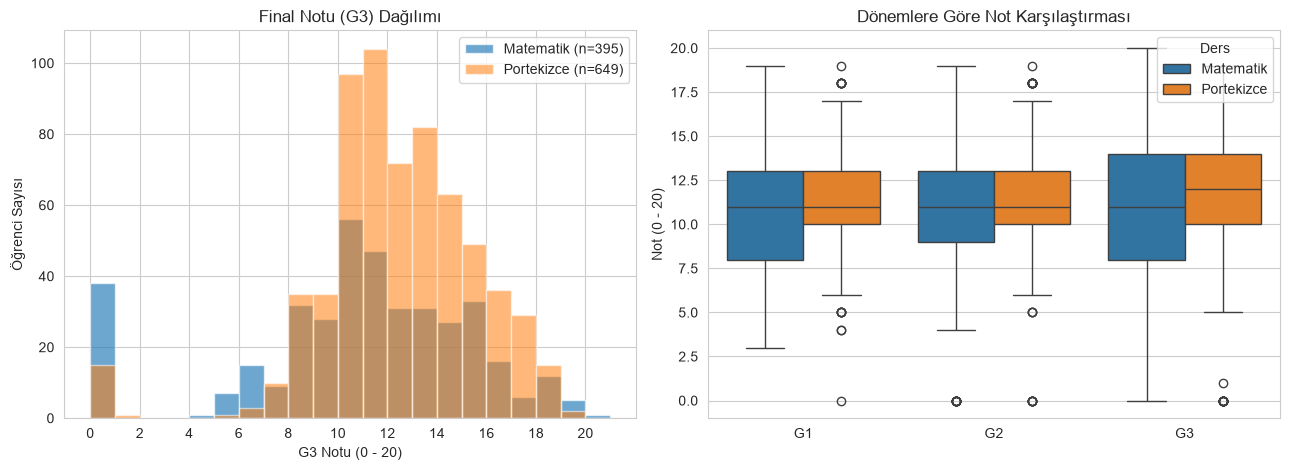

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

bins = range(0, 22)
axes[0].hist(mat_df["G3"], bins=bins, alpha=0.65, color="#1f77b4", edgecolor="white",
             label=f"Matematik (n={len(mat_df)})")
axes[0].hist(por_df["G3"], bins=bins, alpha=0.55, color="#ff7f0e", edgecolor="white",
             label=f"Portekizce (n={len(por_df)})")
axes[0].set_title("Final Notu (G3) Dağılımı")
axes[0].set_xlabel("G3 Notu (0 - 20)")
axes[0].set_ylabel("Öğrenci Sayısı")
axes[0].set_xticks(range(0, 21, 2))
axes[0].legend()

notlar_uzun = pd.concat([
    mat_df[["G1", "G2", "G3"]].assign(Ders="Matematik"),
    por_df[["G1", "G2", "G3"]].assign(Ders="Portekizce")
]).melt(id_vars="Ders", var_name="Dönem", value_name="Not")

sns.boxplot(data=notlar_uzun, x="Dönem", y="Not", hue="Ders", palette=["#1f77b4", "#ff7f0e"], ax=axes[1])
axes[1].set_title("Dönemlere Göre Not Karşılaştırması")
axes[1].set_xlabel("")
axes[1].set_ylabel("Not (0 - 20)")

plt.tight_layout()
plt.show()

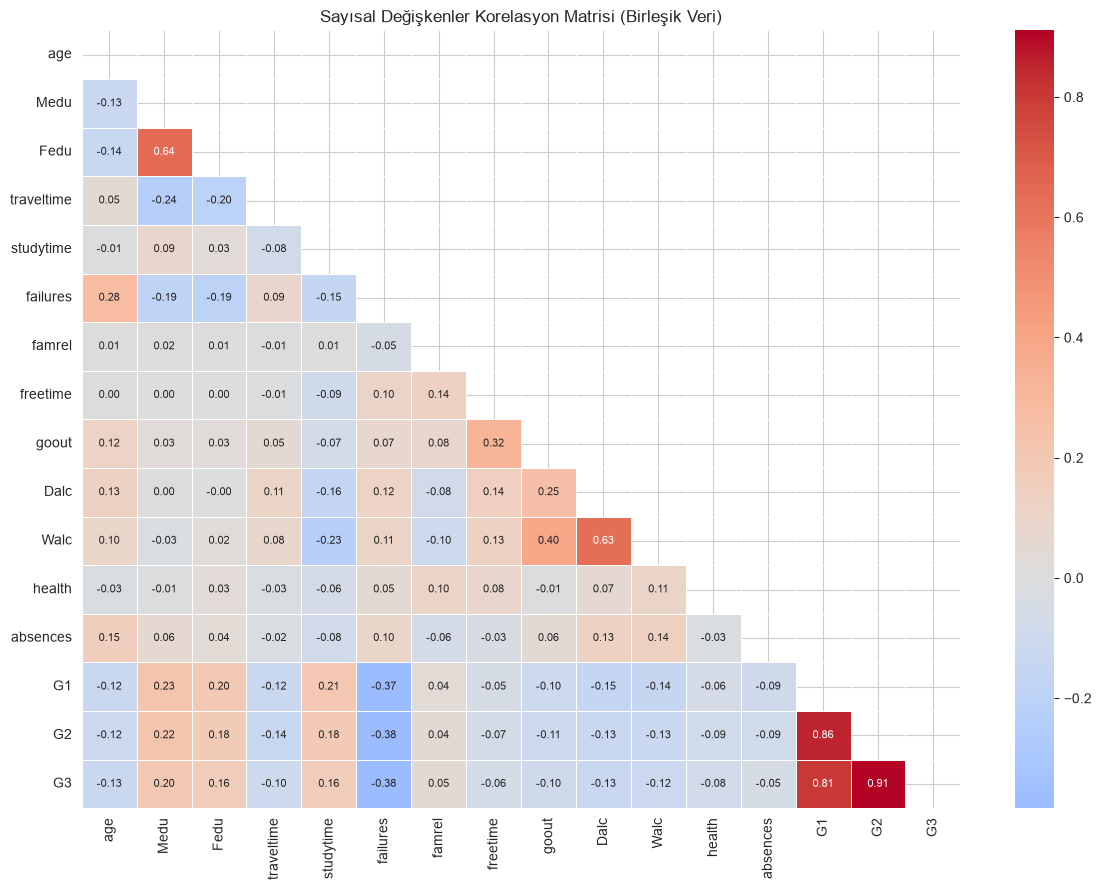

G3 ile en yüksek korelasyona sahip sayısal değişkenler:
G2            0.911
G1            0.809
failures     -0.383
Medu          0.201
studytime     0.162
Fedu          0.160
Dalc         -0.130
age          -0.125
Walc         -0.116
traveltime   -0.103
goout        -0.098
health       -0.080
freetime     -0.065
famrel        0.054
absences     -0.046
Name: G3, dtype: float64


In [6]:
eda_df = pd.concat([
    mat_df.assign(course="mat"),
    por_df.assign(course="por")
], ignore_index=True)

num_cols = eda_df.select_dtypes(include=np.number).columns
corr_mat = eda_df[num_cols].corr()

plt.figure(figsize=(12, 9))
mask = np.triu(np.ones_like(corr_mat, dtype=bool))
sns.heatmap(corr_mat, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            annot_kws={"size": 8}, linewidths=0.4)
plt.title("Sayısal Değişkenler Korelasyon Matrisi (Birleşik Veri)")
plt.tight_layout()
plt.show()

print("G3 ile en yüksek korelasyona sahip sayısal değişkenler:")
print(corr_mat["G3"].drop("G3").sort_values(key=abs, ascending=False).round(3))

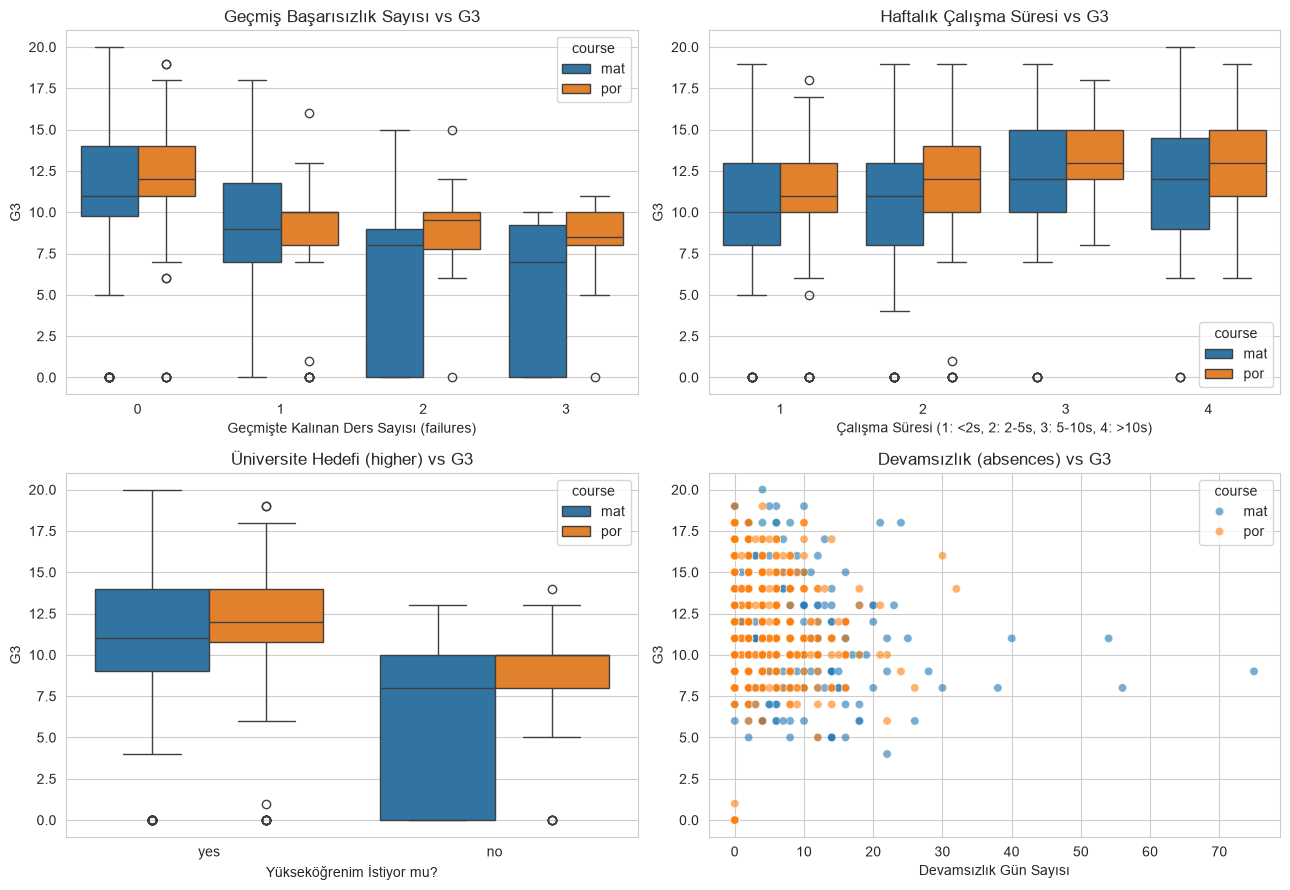

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

sns.boxplot(data=eda_df, x="failures", y="G3", hue="course", palette=["#1f77b4", "#ff7f0e"], ax=axes[0, 0])
axes[0, 0].set_title("Geçmiş Başarısızlık Sayısı vs G3")
axes[0, 0].set_xlabel("Geçmişte Kalınan Ders Sayısı (failures)")

sns.boxplot(data=eda_df, x="studytime", y="G3", hue="course", palette=["#1f77b4", "#ff7f0e"], ax=axes[0, 1])
axes[0, 1].set_title("Haftalık Çalışma Süresi vs G3")
axes[0, 1].set_xlabel("Çalışma Süresi (1: <2s, 2: 2-5s, 3: 5-10s, 4: >10s)")

sns.boxplot(data=eda_df, x="higher", y="G3", hue="course", palette=["#1f77b4", "#ff7f0e"], ax=axes[1, 0])
axes[1, 0].set_title("Üniversite Hedefi (higher) vs G3")
axes[1, 0].set_xlabel("Yükseköğrenim İstiyor mu?")

sns.scatterplot(data=eda_df, x="absences", y="G3", hue="course", palette=["#1f77b4", "#ff7f0e"], alpha=0.6, ax=axes[1, 1])
axes[1, 1].set_title("Devamsızlık (absences) vs G3")
axes[1, 1].set_xlabel("Devamsızlık Gün Sayısı")

plt.tight_layout()
plt.show()

In [8]:
from sklearn.model_selection import GroupShuffleSplit, GroupKFold

df = pd.concat([
    mat_df.assign(course="mat"),
    por_df.assign(course="por")
], ignore_index=True)

df["student_group"] = df.groupby(ortak_anahtar, sort=False).ngroup()

gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, test_idx = next(gss.split(df, df["G3"], groups=df["student_group"]))

train_df = df.iloc[train_idx].reset_index(drop=True)
test_df = df.iloc[test_idx].reset_index(drop=True)

kesisim = set(train_df["student_group"]).intersection(set(test_df["student_group"]))
assert len(kesisim) == 0, "Eğitim ve test setinde ortak öğrenci grubu var!"

print(f"Toplam satır: {len(df)} | Tekil öğrenci grubu: {df['student_group'].nunique()}")
print(f"Eğitim seti: {train_df.shape} | Test seti: {test_df.shape}")
print(f"Eğitim G3 ortalama: {train_df['G3'].mean():.2f} | Test G3 ortalama: {test_df['G3'].mean():.2f}")
print("Ortak grup kesişimi:", len(kesisim))
print("Ders dağılımı (Train):", train_df["course"].value_counts().to_dict())
print("Ders dağılımı (Test): ", test_df["course"].value_counts().to_dict())

Toplam satır: 1044 | Tekil öğrenci grubu: 662
Eğitim seti: (831, 35) | Test seti: (213, 35)
Eğitim G3 ortalama: 11.38 | Test G3 ortalama: 11.21
Ortak grup kesişimi: 0
Ders dağılımı (Train): {'por': 521, 'mat': 310}
Ders dağılımı (Test):  {'por': 128, 'mat': 85}


In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.model_selection import cross_validate
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor, plot_tree, export_text
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

binary_cols = [
    "school", "sex", "address", "famsize", "Pstatus",
    "schoolsup", "famsup", "paid", "activities", "nursery",
    "higher", "internet", "romantic", "course"
]
nominal_cols = ["Mjob", "Fjob", "reason", "guardian"]

def build_preprocessor(feature_cols):
    num_cols = [c for c in feature_cols if c not in binary_cols and c not in nominal_cols]
    bin_cols = [c for c in feature_cols if c in binary_cols]
    nom_cols = [c for c in feature_cols if c in nominal_cols]

    num_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    bin_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))
    ])
    nom_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ])

    return ColumnTransformer(
        transformers=[
            ("num", num_pipe, num_cols),
            ("bin", bin_pipe, bin_cols),
            ("nom", nom_pipe, nom_cols),
        ],
        verbose_feature_names_out=False
    )

def evaluate_models(models, X_tr, y_tr, groups_tr, X_te, y_te):
    feature_cols = list(X_tr.columns)
    cv = GroupKFold(n_splits=5)
    rows = []

    for name, estimator in models.items():
        pipe = Pipeline([
            ("prep", build_preprocessor(feature_cols)),
            ("model", estimator)
        ])
        cv_res = cross_validate(
            pipe, X_tr, y_tr, groups=groups_tr, cv=cv,
            scoring={
                "rmse": "neg_root_mean_squared_error",
                "mae": "neg_mean_absolute_error",
                "r2": "r2"
            },
            n_jobs=1
        )
        pipe.fit(X_tr, y_tr)
        pred_tr = pipe.predict(X_tr)
        pred_te = pipe.predict(X_te)

        rows.append({
            "Model": name,
            "CV_RMSE": -cv_res["test_rmse"].mean(),
            "CV_MAE": -cv_res["test_mae"].mean(),
            "CV_R2": cv_res["test_r2"].mean(),
            "Train_RMSE": root_mean_squared_error(y_tr, pred_tr),
            "Test_RMSE": root_mean_squared_error(y_te, pred_te),
            "Test_MAE": mean_absolute_error(y_te, pred_te),
            "Test_R2": r2_score(y_te, pred_te),
        })

    return pd.DataFrame(rows).sort_values("CV_RMSE").reset_index(drop=True)

drop_meta = ["G3", "student_group"]
s1_features = [c for c in train_df.columns if c not in drop_meta]

base_models = {
    "Dummy (Ortalama)": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Ridge (alpha=10)": Ridge(alpha=10.0),
    "Karar Ağacı (Sınırsız Derinlik)": DecisionTreeRegressor(random_state=42),
    "Karar Ağacı (max_depth=4)": DecisionTreeRegressor(max_depth=4, min_samples_leaf=10, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}

s1_results = evaluate_models(
    base_models,
    train_df[s1_features], train_df["G3"], train_df["student_group"],
    test_df[s1_features], test_df["G3"]
)
display(s1_results.round(3))

,Model,CV_RMSE,CV_MAE,CV_R2,Train_RMSE,Test_RMSE,Test_MAE,Test_R2
0,Gradient Boosting,1.512,0.918,0.845,1.015,1.334,0.906,0.884
1,Random Forest,1.567,0.950,0.833,0.561,1.272,0.853,0.895
2,Karar Ağacı (max_depth=4),1.567,0.935,0.831,1.475,1.239,0.831,0.900
3,Ridge (alpha=10),1.651,1.009,0.815,1.545,1.444,1.009,0.865
4,Linear Regression,1.662,1.024,0.813,1.543,1.444,1.011,0.865
5,Karar Ağacı (Sınırsız Derinlik),2.110,1.177,0.696,0.000,1.630,0.948,0.827
6,Dummy (Ortalama),3.845,2.824,-0.005,3.846,3.928,2.865,-0.002


,Model,CV_RMSE,Train_RMSE,Test_RMSE,Test_MAE,Test_R2
0,Budanmış Karar Ağacı (FE),1.585,1.366,1.317,0.849,0.887
1,Tuned Random Forest (FE),1.498,1.260,1.244,0.810,0.900
2,Tuned Gradient Boosting (FE),1.467,1.325,1.264,0.865,0.896


Senaryo 1 Budanmış Karar Ağacı en iyi parametreleri:
{'ccp_alpha': 0.0, 'max_depth': 5, 'min_samples_leaf': 15, 'min_samples_split': 10}


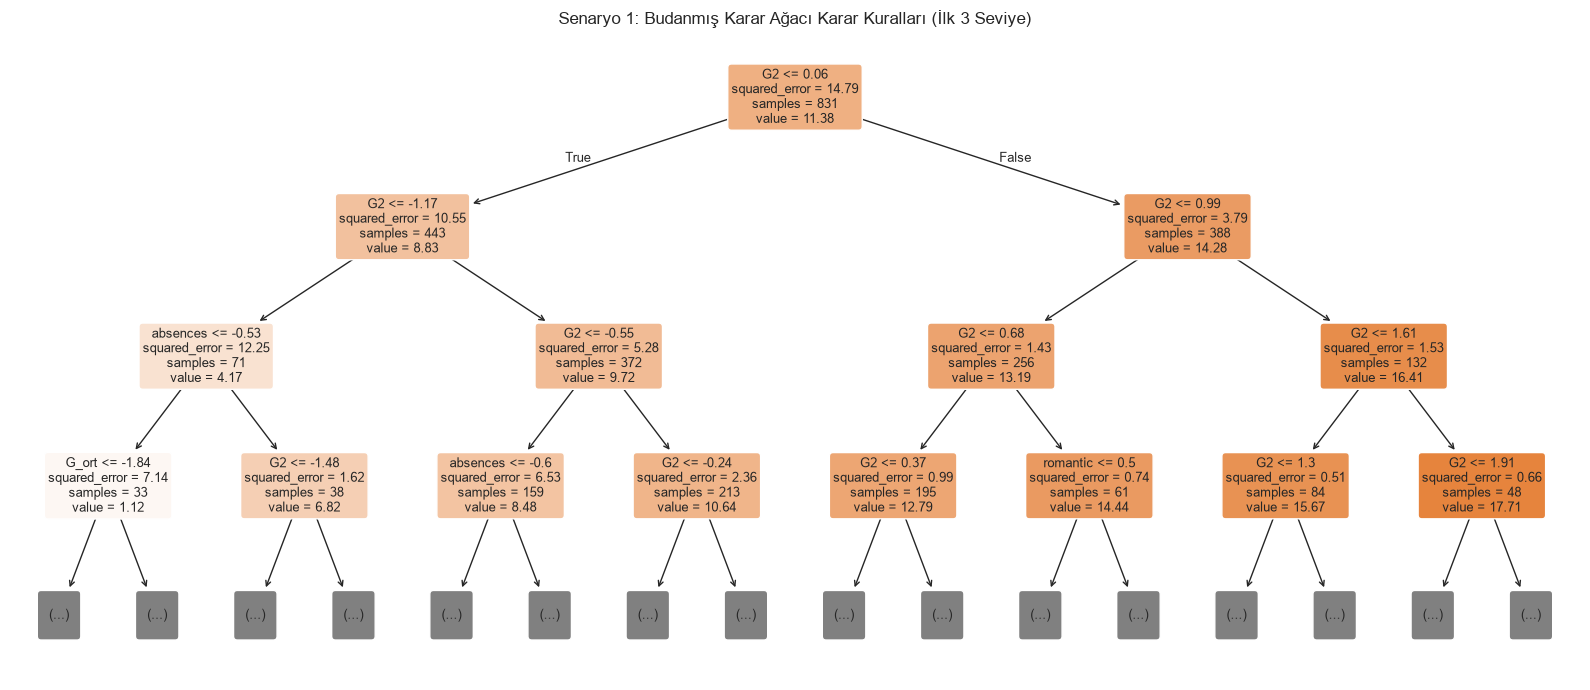

In [10]:
from sklearn.model_selection import GridSearchCV

def add_s1_features(data):
    d = data.copy()
    d["G_ort"] = (d["G1"] + d["G2"]) / 2.0
    d["G_degisim"] = d["G2"] - d["G1"]
    d["G2_sifir_mi"] = (d["G2"] == 0).astype(int)
    return d

train_s1_fe = add_s1_features(train_df)
test_s1_fe = add_s1_features(test_df)
s1_fe_features = [c for c in train_s1_fe.columns if c not in drop_meta]

cv_gkf = GroupKFold(n_splits=5)

dt_s1_grid = GridSearchCV(
    Pipeline([
        ("prep", build_preprocessor(s1_fe_features)),
        ("model", DecisionTreeRegressor(random_state=42))
    ]),
    param_grid={
        "model__max_depth": [3, 4, 5, 6, 7],
        "model__min_samples_split": [10, 20, 30],
        "model__min_samples_leaf": [5, 10, 15, 20],
        "model__ccp_alpha": [0.0, 0.01, 0.03, 0.05]
    },
    cv=cv_gkf,
    scoring="neg_root_mean_squared_error",
    n_jobs=1
)
dt_s1_grid.fit(train_s1_fe[s1_fe_features], train_s1_fe["G3"], groups=train_s1_fe["student_group"])

rf_s1_grid = GridSearchCV(
    Pipeline([
        ("prep", build_preprocessor(s1_fe_features)),
        ("model", RandomForestRegressor(random_state=42))
    ]),
    param_grid={
        "model__n_estimators": [300],
        "model__max_depth": [4, 6, 8],
        "model__min_samples_leaf": [5, 10]
    },
    cv=cv_gkf,
    scoring="neg_root_mean_squared_error",
    n_jobs=1
)
rf_s1_grid.fit(train_s1_fe[s1_fe_features], train_s1_fe["G3"], groups=train_s1_fe["student_group"])

gb_s1_grid = GridSearchCV(
    Pipeline([
        ("prep", build_preprocessor(s1_fe_features)),
        ("model", GradientBoostingRegressor(random_state=42))
    ]),
    param_grid={
        "model__n_estimators": [100, 200],
        "model__max_depth": [2, 3],
        "model__learning_rate": [0.03, 0.05],
        "model__min_samples_leaf": [5, 10]
    },
    cv=cv_gkf,
    scoring="neg_root_mean_squared_error",
    n_jobs=1
)
gb_s1_grid.fit(train_s1_fe[s1_fe_features], train_s1_fe["G3"], groups=train_s1_fe["student_group"])

tuned_s1_rows = []
for label, gs in [
    ("Budanmış Karar Ağacı (FE)", dt_s1_grid),
    ("Tuned Random Forest (FE)", rf_s1_grid),
    ("Tuned Gradient Boosting (FE)", gb_s1_grid),
]:
    best_model = gs.best_estimator_
    pred_tr = best_model.predict(train_s1_fe[s1_fe_features])
    pred_te = best_model.predict(test_s1_fe[s1_fe_features])
    tuned_s1_rows.append({
        "Model": label,
        "CV_RMSE": -gs.best_score_,
        "Train_RMSE": root_mean_squared_error(train_s1_fe["G3"], pred_tr),
        "Test_RMSE": root_mean_squared_error(test_s1_fe["G3"], pred_te),
        "Test_MAE": mean_absolute_error(test_s1_fe["G3"], pred_te),
        "Test_R2": r2_score(test_s1_fe["G3"], pred_te),
    })

tuned_s1_df = pd.DataFrame(tuned_s1_rows)
display(tuned_s1_df.round(3))

print("Senaryo 1 Budanmış Karar Ağacı en iyi parametreleri:")
print({k.replace("model__", ""): v for k, v in dt_s1_grid.best_params_.items()})

best_s1_pipe = dt_s1_grid.best_estimator_
s1_pred_test = best_s1_pipe.predict(test_s1_fe[s1_fe_features])

dt_s1_model = best_s1_pipe.named_steps["model"]
dt_s1_feat_names = list(best_s1_pipe.named_steps["prep"].get_feature_names_out())

plt.figure(figsize=(16, 7))
plot_tree(
    dt_s1_model,
    feature_names=dt_s1_feat_names,
    max_depth=3,
    filled=True,
    rounded=True,
    fontsize=9,
    precision=2
)
plt.title("Senaryo 1: Budanmış Karar Ağacı Karar Kuralları (İlk 3 Seviye)")
plt.tight_layout()
plt.show()

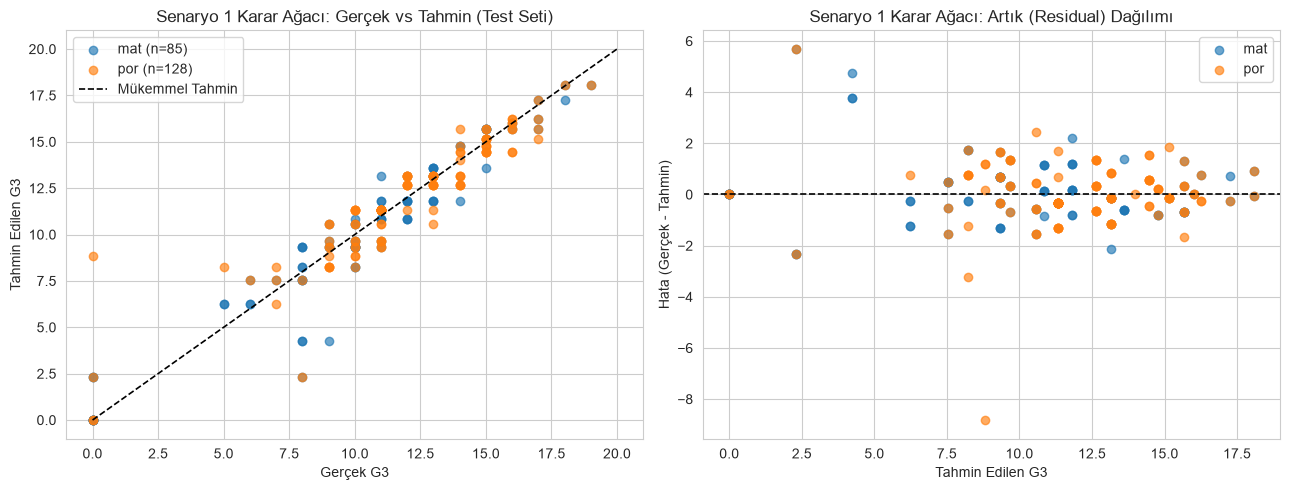

Test Seti Ders Bazlı Kırılım (Birleşik Karar Ağacı Modeli):
  mat: RMSE=1.349, MAE=0.910, R2=0.909
  por: RMSE=1.296, MAE=0.808, R2=0.851

Aynı Test Setinde Derslere Özel Ayrı Karar Ağacı Modelleri:
  mat (Ayrı Karar Ağacı): RMSE=1.536, MAE=0.917, R2=0.883
  por (Ayrı Karar Ağacı): RMSE=1.464, MAE=0.892, R2=0.810

En yüksek hata yapılan ilk 8 test örneği:


,course,G1,G2,G3,absences,failures,Tahmin,Hata,Mutlak_Hata
124,por,11,9,0,0,2,8.82,-8.82,8.82
179,por,7,7,8,0,3,2.31,5.69,5.69
25,mat,7,7,8,0,0,2.31,5.69,5.69
2,mat,10,8,9,0,0,4.24,4.76,4.76
53,mat,6,8,8,0,1,4.24,3.76,3.76
55,mat,8,9,8,0,0,4.24,3.76,3.76
140,por,7,8,5,12,3,8.24,-3.24,3.24
176,por,13,10,13,0,0,10.56,2.44,2.44


In [11]:
test_diag_s1 = test_s1_fe[["course", "G1", "G2", "G3", "absences", "failures"]].copy()
test_diag_s1["Tahmin"] = s1_pred_test
test_diag_s1["Hata"] = test_diag_s1["G3"] - test_diag_s1["Tahmin"]
test_diag_s1["Mutlak_Hata"] = test_diag_s1["Hata"].abs()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for c_name, col_hex in [("mat", "#1f77b4"), ("por", "#ff7f0e")]:
    sub = test_diag_s1[test_diag_s1["course"] == c_name]
    axes[0].scatter(sub["G3"], sub["Tahmin"], alpha=0.65, color=col_hex, label=f"{c_name} (n={len(sub)})")
axes[0].plot([0, 20], [0, 20], "k--", lw=1.2, label="Mükemmel Tahmin")
axes[0].set_title("Senaryo 1 Karar Ağacı: Gerçek vs Tahmin (Test Seti)")
axes[0].set_xlabel("Gerçek G3")
axes[0].set_ylabel("Tahmin Edilen G3")
axes[0].legend()

for c_name, col_hex in [("mat", "#1f77b4"), ("por", "#ff7f0e")]:
    sub = test_diag_s1[test_diag_s1["course"] == c_name]
    axes[1].scatter(sub["Tahmin"], sub["Hata"], alpha=0.65, color=col_hex, label=c_name)
axes[1].axhline(0, color="black", linestyle="--", lw=1.2)
axes[1].set_title("Senaryo 1 Karar Ağacı: Artık (Residual) Dağılımı")
axes[1].set_xlabel("Tahmin Edilen G3")
axes[1].set_ylabel("Hata (Gerçek - Tahmin)")
axes[1].legend()

plt.tight_layout()
plt.show()

print("Test Seti Ders Bazlı Kırılım (Birleşik Karar Ağacı Modeli):")
for c_name in ["mat", "por"]:
    sub = test_diag_s1[test_diag_s1["course"] == c_name]
    print(
        f"  {c_name}: RMSE={root_mean_squared_error(sub['G3'], sub['Tahmin']):.3f}, "
        f"MAE={mean_absolute_error(sub['G3'], sub['Tahmin']):.3f}, "
        f"R2={r2_score(sub['G3'], sub['Tahmin']):.3f}"
    )

dt_best_params = {k.replace("model__", ""): v for k, v in dt_s1_grid.best_params_.items()}
print("\nAynı Test Setinde Derslere Özel Ayrı Karar Ağacı Modelleri:")
for c_name in ["mat", "por"]:
    tr_sub = train_s1_fe[train_s1_fe["course"] == c_name]
    te_sub = test_s1_fe[test_s1_fe["course"] == c_name]
    sub_feats = [c for c in s1_fe_features if c != "course"]
    sub_pipe = Pipeline([
        ("prep", build_preprocessor(sub_feats)),
        ("model", DecisionTreeRegressor(random_state=42, **dt_best_params))
    ])
    sub_pipe.fit(tr_sub[sub_feats], tr_sub["G3"])
    sub_pred = sub_pipe.predict(te_sub[sub_feats])
    print(
        f"  {c_name} (Ayrı Karar Ağacı): RMSE={root_mean_squared_error(te_sub['G3'], sub_pred):.3f}, "
        f"MAE={mean_absolute_error(te_sub['G3'], sub_pred):.3f}, "
        f"R2={r2_score(te_sub['G3'], sub_pred):.3f}"
    )

print("\nEn yüksek hata yapılan ilk 8 test örneği:")
display(test_diag_s1.sort_values("Mutlak_Hata", ascending=False).head(8).round(2))

In [12]:
s2_features = [c for c in train_df.columns if c not in ["G1", "G2", "G3", "student_group"]]

s2_results = evaluate_models(
    base_models,
    train_df[s2_features], train_df["G3"], train_df["student_group"],
    test_df[s2_features], test_df["G3"]
)
display(s2_results.round(3))

,Model,CV_RMSE,CV_MAE,CV_R2,Train_RMSE,Test_RMSE,Test_MAE,Test_R2
0,Random Forest,3.268,2.370,0.271,1.167,3.001,2.266,0.415
1,Gradient Boosting,3.405,2.510,0.211,2.396,2.914,2.239,0.449
2,Karar Ağacı (max_depth=4),3.464,2.541,0.184,3.208,3.147,2.394,0.357
3,Ridge (alpha=10),3.543,2.560,0.146,3.323,3.159,2.386,0.352
4,Linear Regression,3.560,2.580,0.138,3.321,3.161,2.393,0.351
5,Dummy (Ortalama),3.845,2.824,-0.005,3.846,3.928,2.865,-0.002
6,Karar Ağacı (Sınırsız Derinlik),4.639,3.308,-0.482,0.000,4.443,3.141,-0.282


,Model,CV_RMSE,Train_RMSE,Test_RMSE,Test_MAE,Test_R2
0,Budanmış Karar Ağacı (FE),3.400,3.331,3.170,2.418,0.348
1,Tuned Random Forest (FE),3.295,2.396,2.982,2.287,0.423
2,Tuned Gradient Boosting (FE),3.330,2.869,2.901,2.212,0.454


Senaryo 2 Budanmış Karar Ağacı en iyi parametreleri:
{'ccp_alpha': 0.1, 'max_depth': 3, 'min_samples_leaf': 15, 'min_samples_split': 10}


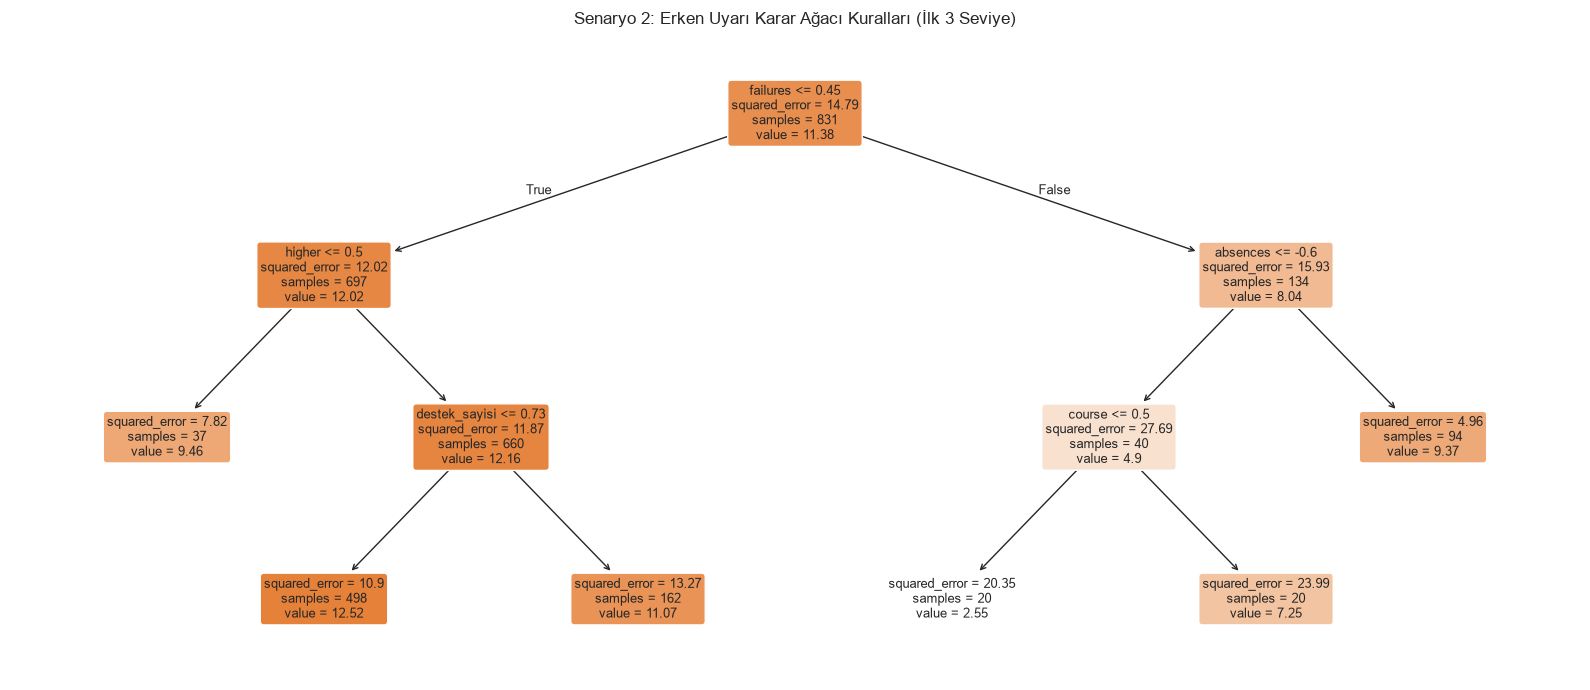

In [13]:
def add_s2_features(data):
    d = data.copy()
    d["ebeveyn_egitim_ort"] = (d["Medu"] + d["Fedu"]) / 2.0
    d["alkol_toplam"] = d["Dalc"] + d["Walc"]
    d["sosyal_yuk"] = d["freetime"] + d["goout"]
    d["devamsizlik_log"] = np.log1p(d["absences"])
    d["destek_sayisi"] = (
        (d["schoolsup"] == "yes").astype(int)
        + (d["famsup"] == "yes").astype(int)
        + (d["paid"] == "yes").astype(int)
    )
    return d

train_s2_fe = add_s2_features(train_df)
test_s2_fe = add_s2_features(test_df)
s2_fe_features = [c for c in train_s2_fe.columns if c not in ["G1", "G2", "G3", "student_group"]]

dt_s2_grid = GridSearchCV(
    Pipeline([
        ("prep", build_preprocessor(s2_fe_features)),
        ("model", DecisionTreeRegressor(random_state=42))
    ]),
    param_grid={
        "model__max_depth": [3, 4, 5, 6],
        "model__min_samples_split": [10, 20, 40],
        "model__min_samples_leaf": [10, 15, 25, 35],
        "model__ccp_alpha": [0.0, 0.02, 0.05, 0.1]
    },
    cv=cv_gkf,
    scoring="neg_root_mean_squared_error",
    n_jobs=1
)
dt_s2_grid.fit(train_s2_fe[s2_fe_features], train_s2_fe["G3"], groups=train_s2_fe["student_group"])

rf_s2_grid = GridSearchCV(
    Pipeline([
        ("prep", build_preprocessor(s2_fe_features)),
        ("model", RandomForestRegressor(random_state=42))
    ]),
    param_grid={
        "model__n_estimators": [300],
        "model__max_depth": [5, 7, 9],
        "model__min_samples_leaf": [5, 10, 15]
    },
    cv=cv_gkf,
    scoring="neg_root_mean_squared_error",
    n_jobs=1
)
rf_s2_grid.fit(train_s2_fe[s2_fe_features], train_s2_fe["G3"], groups=train_s2_fe["student_group"])

gb_s2_grid = GridSearchCV(
    Pipeline([
        ("prep", build_preprocessor(s2_fe_features)),
        ("model", GradientBoostingRegressor(random_state=42))
    ]),
    param_grid={
        "model__n_estimators": [80, 150],
        "model__max_depth": [2, 3],
        "model__learning_rate": [0.03, 0.05],
        "model__min_samples_leaf": [5, 10, 15]
    },
    cv=cv_gkf,
    scoring="neg_root_mean_squared_error",
    n_jobs=1
)
gb_s2_grid.fit(train_s2_fe[s2_fe_features], train_s2_fe["G3"], groups=train_s2_fe["student_group"])

tuned_s2_rows = []
for label, gs in [
    ("Budanmış Karar Ağacı (FE)", dt_s2_grid),
    ("Tuned Random Forest (FE)", rf_s2_grid),
    ("Tuned Gradient Boosting (FE)", gb_s2_grid),
]:
    best_model = gs.best_estimator_
    pred_tr = best_model.predict(train_s2_fe[s2_fe_features])
    pred_te = best_model.predict(test_s2_fe[s2_fe_features])
    tuned_s2_rows.append({
        "Model": label,
        "CV_RMSE": -gs.best_score_,
        "Train_RMSE": root_mean_squared_error(train_s2_fe["G3"], pred_tr),
        "Test_RMSE": root_mean_squared_error(test_s2_fe["G3"], pred_te),
        "Test_MAE": mean_absolute_error(test_s2_fe["G3"], pred_te),
        "Test_R2": r2_score(test_s2_fe["G3"], pred_te),
    })

tuned_s2_df = pd.DataFrame(tuned_s2_rows)
display(tuned_s2_df.round(3))

print("Senaryo 2 Budanmış Karar Ağacı en iyi parametreleri:")
print({k.replace("model__", ""): v for k, v in dt_s2_grid.best_params_.items()})

best_s2_pipe = dt_s2_grid.best_estimator_
s2_pred_test = best_s2_pipe.predict(test_s2_fe[s2_fe_features])

dt_s2_model = best_s2_pipe.named_steps["model"]
dt_s2_feat_names = list(best_s2_pipe.named_steps["prep"].get_feature_names_out())

plt.figure(figsize=(16, 7))
plot_tree(
    dt_s2_model,
    feature_names=dt_s2_feat_names,
    max_depth=3,
    filled=True,
    rounded=True,
    fontsize=9,
    precision=2
)
plt.title("Senaryo 2: Erken Uyarı Karar Ağacı Kuralları (İlk 3 Seviye)")
plt.tight_layout()
plt.show()

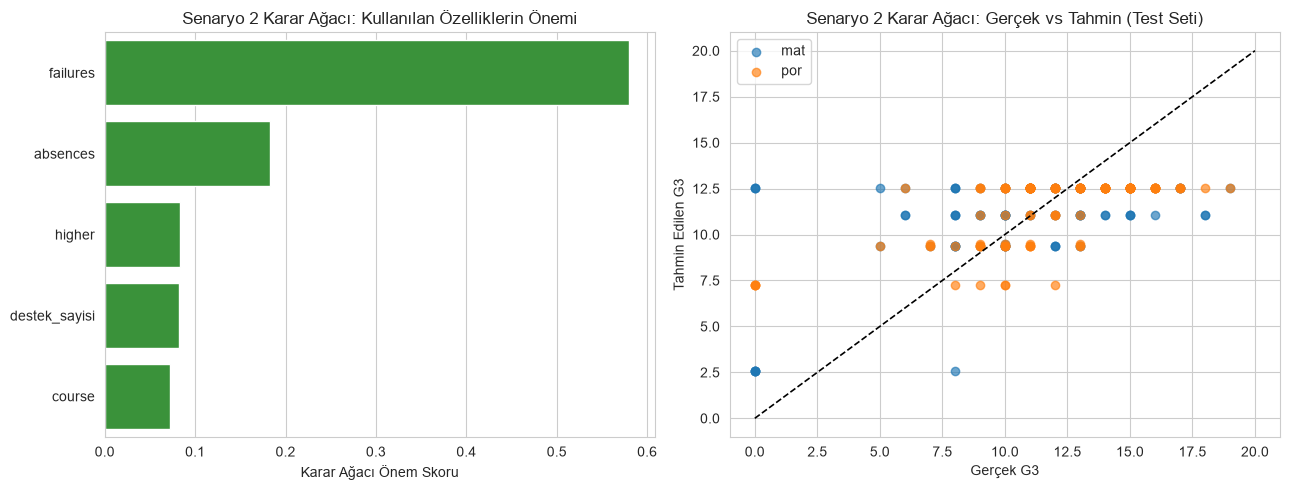

Senaryo 2 Karar Ağacı Ders Bazlı Test Sonuçları:
  mat: RMSE=3.832, MAE=2.879, R2=0.269
  por: RMSE=2.640, MAE=2.112, R2=0.384

Geçme/Kalma (G3 >= 10) Eşiği Üzerinden Karar Ağacı Başarısı:
  Senaryo 1 (Regresyon Ağacı >= 10) -> Doğruluk: 0.878 | F1: 0.914
  Senaryo 2 (Regresyon Ağacı >= 10) -> Doğruluk: 0.775 | F1: 0.850
  Senaryo 2 (DecisionTreeClassifier) -> Doğruluk: 0.798 | F1: 0.875


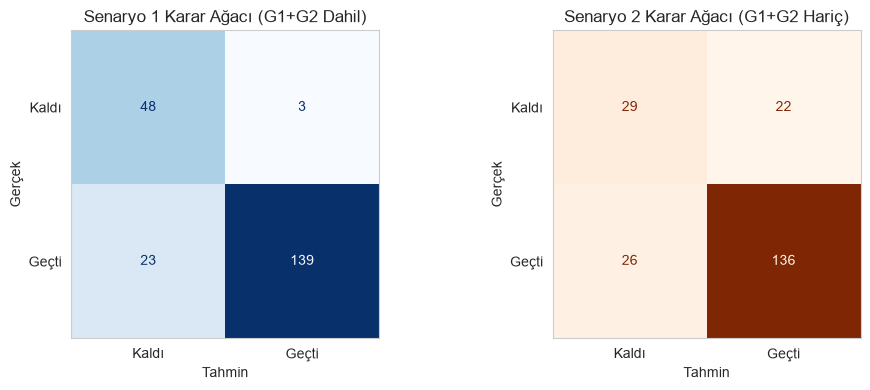

In [14]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

dt_imp_df = pd.DataFrame({
    "Özellik": dt_s2_feat_names,
    "Önem": dt_s2_model.feature_importances_
}).sort_values("Önem", ascending=False)
dt_imp_df = dt_imp_df[dt_imp_df["Önem"] > 0].head(10)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(data=dt_imp_df, x="Önem", y="Özellik", color="#2ca02c", ax=axes[0])
axes[0].set_title("Senaryo 2 Karar Ağacı: Kullanılan Özelliklerin Önemi")
axes[0].set_xlabel("Karar Ağacı Önem Skoru")
axes[0].set_ylabel("")

for c_name, col_hex in [("mat", "#1f77b4"), ("por", "#ff7f0e")]:
    mask_c = test_s2_fe["course"] == c_name
    axes[1].scatter(test_s2_fe.loc[mask_c, "G3"], s2_pred_test[mask_c], alpha=0.65, color=col_hex, label=c_name)
axes[1].plot([0, 20], [0, 20], "k--", lw=1.2)
axes[1].set_title("Senaryo 2 Karar Ağacı: Gerçek vs Tahmin (Test Seti)")
axes[1].set_xlabel("Gerçek G3")
axes[1].set_ylabel("Tahmin Edilen G3")
axes[1].legend()

plt.tight_layout()
plt.show()

print("Senaryo 2 Karar Ağacı Ders Bazlı Test Sonuçları:")
for c_name in ["mat", "por"]:
    mask_c = test_s2_fe["course"] == c_name
    print(
        f"  {c_name}: RMSE={root_mean_squared_error(test_s2_fe.loc[mask_c, 'G3'], s2_pred_test[mask_c]):.3f}, "
        f"MAE={mean_absolute_error(test_s2_fe.loc[mask_c, 'G3'], s2_pred_test[mask_c]):.3f}, "
        f"R2={r2_score(test_s2_fe.loc[mask_c, 'G3'], s2_pred_test[mask_c]):.3f}"
    )

y_pass_tr = (train_df["G3"] >= 10).astype(int)
y_pass_true = (test_df["G3"] >= 10).astype(int)

s1_pass_pred = (s1_pred_test >= 10).astype(int)
s2_pass_pred = (s2_pred_test >= 10).astype(int)

clf_s2_pipe = Pipeline([
    ("prep", build_preprocessor(s2_fe_features)),
    ("model", DecisionTreeClassifier(max_depth=4, min_samples_leaf=20, random_state=42))
])
clf_s2_pipe.fit(train_s2_fe[s2_fe_features], y_pass_tr)
clf_s2_pred = clf_s2_pipe.predict(test_s2_fe[s2_fe_features])

print("\nGeçme/Kalma (G3 >= 10) Eşiği Üzerinden Karar Ağacı Başarısı:")
print(f"  Senaryo 1 (Regresyon Ağacı >= 10) -> Doğruluk: {accuracy_score(y_pass_true, s1_pass_pred):.3f} | F1: {f1_score(y_pass_true, s1_pass_pred):.3f}")
print(f"  Senaryo 2 (Regresyon Ağacı >= 10) -> Doğruluk: {accuracy_score(y_pass_true, s2_pass_pred):.3f} | F1: {f1_score(y_pass_true, s2_pass_pred):.3f}")
print(f"  Senaryo 2 (DecisionTreeClassifier) -> Doğruluk: {accuracy_score(y_pass_true, clf_s2_pred):.3f} | F1: {f1_score(y_pass_true, clf_s2_pred):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(confusion_matrix(y_pass_true, s1_pass_pred), display_labels=["Kaldı", "Geçti"]).plot(
    ax=axes[0], cmap="Blues", colorbar=False
)
axes[0].grid(False)
axes[0].set_title("Senaryo 1 Karar Ağacı (G1+G2 Dahil)")
axes[0].set_xlabel("Tahmin")
axes[0].set_ylabel("Gerçek")

ConfusionMatrixDisplay(confusion_matrix(y_pass_true, s2_pass_pred), display_labels=["Kaldı", "Geçti"]).plot(
    ax=axes[1], cmap="Oranges", colorbar=False
)
axes[1].grid(False)
axes[1].set_title("Senaryo 2 Karar Ağacı (G1+G2 Hariç)")
axes[1].set_xlabel("Tahmin")
axes[1].set_ylabel("Gerçek")

plt.tight_layout()
plt.show()